In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

In [35]:
DataTrain

,x,y,Predicted_X,Predicted_y
0,24,21.549452,23.908488,23.908488
1,50,47.464463,49.925554,49.925554
2,15,17.218656,14.902580,14.902580
3,38,36.586398,37.917677,37.917677
4,87,87.288984,86.949840,86.949840
...,...,...,...,...
694,58,58.595006,57.930805,57.930805
695,93,94.625094,92.953778,92.953778
696,82,88.603770,81.946558,81.946558
697,66,63.648685,65.936056,65.936056


In [33]:
DataTrain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   x            699 non-null    int64  
 1   y            699 non-null    float64
 2   Predicted_X  699 non-null    float64
 3   Predicted_y  699 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 22.0 KB


In [13]:
DataTrain.describe

,x,y
count,699.000000,699.000000
mean,50.014306,49.939869
std,28.954560,29.109217
min,0.000000,-3.839981
25%,25.000000,24.929968
50%,49.000000,48.973020
75%,75.000000,74.929911
max,100.000000,108.871618


In [45]:
model = LinearRegression()

In [46]:
model.fit(X,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
X = DataTrain[['x']]
Y = DataTrain[['y']]
model = LinearRegression()
model.fit(X,Y)

print("Regression coefficient (slope):", model.coef_[0])
print("Intercept:", model.intercept_)
print("R-squared:", model.score(X, Y))

Regression coefficient (slope): [1.00065638]
Intercept: [-0.10726546]
R-squared: 0.9907015319025518


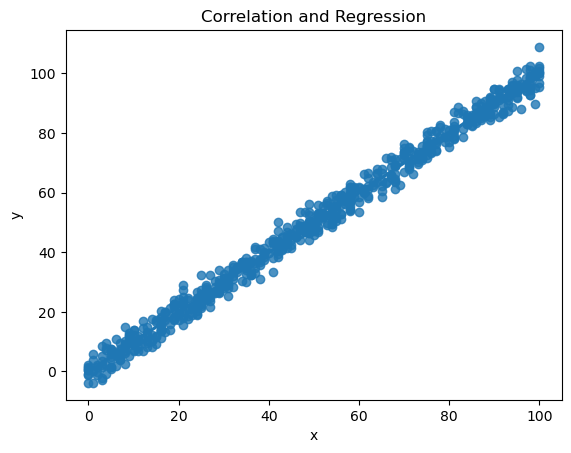

In [18]:

sns.regplot(data=DataTrain, x='x', y='y')

plt.title('Correlation and Regression')
plt.show()

In [26]:
import statsmodels.api as sm

X = DataTrain[['x']]  # Replace with your X column
y = DataTrain[['y']]       # Replace with your Y column

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()

alpha = 0.01

print(model.summary())
print("\n95% Confidence Intervals:")
print(model.conf_int(alpha=alpha))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.991
Model:                            OLS   Adj. R-squared:                  0.991
Method:                 Least Squares   F-statistic:                 7.426e+04
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:05:08   Log-Likelihood:                -1712.8
No. Observations:                 699   AIC:                             3430.
Df Residuals:                     697   BIC:                             3439.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1073      0.212     -0.506      0.6

In [29]:
# Calculate predicted values using your fitted regression model
DataTrain['Predicted_X'] = model.predict(X)

# Display the updated DataFrame
DataTrain

,x,y,Predicted_X
0,24,21.549452,23.908488
1,50,47.464463,49.925554
2,15,17.218656,14.902580
3,38,36.586398,37.917677
4,87,87.288984,86.949840
...,...,...,...
694,58,58.595006,57.930805
695,93,94.625094,92.953778
696,82,88.603770,81.946558
697,66,63.648685,65.936056


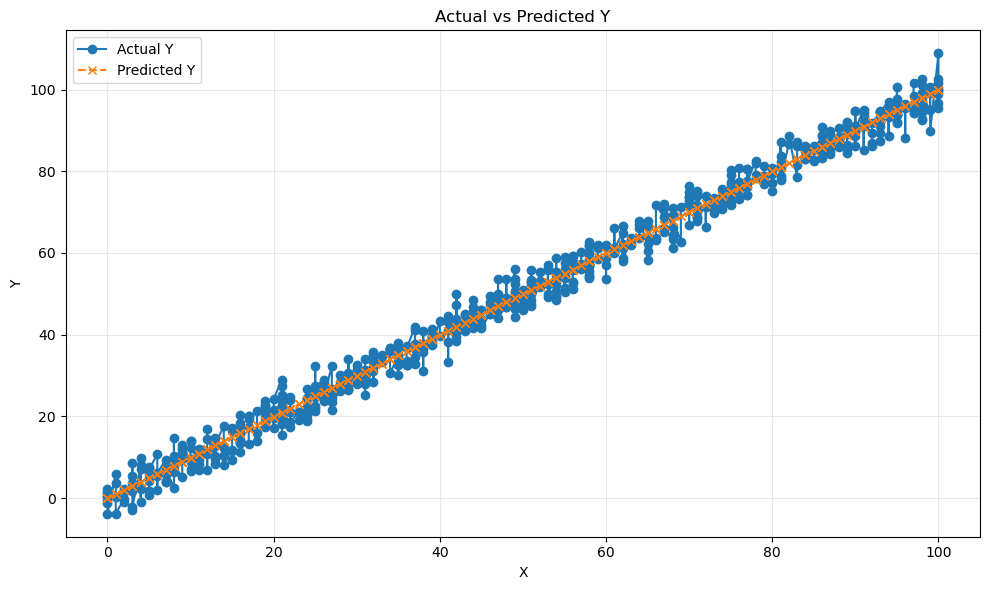

In [31]:
import matplotlib.pyplot as plt

# Calculate predicted Y values
DataTrain['Predicted_y'] = model.predict(X)

# Sort by X so the lines appear correctly
DataPlot = DataTrain.sort_values(by='x')

# Plot actual and predicted values
plt.figure(figsize=(10, 6))

plt.plot(DataPlot['x'], DataPlot['y'],
         label='Actual Y', marker='o')

plt.plot(DataPlot['x'], DataPlot['Predicted_y'],
         label='Predicted Y', linestyle='--', marker='x')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Actual vs Predicted Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()